# چالش سوم: تصمیم‌گیری پرهزینه و طبقه‌بندی حساس به هزینه (Cost-Sensitive Credit Risk Engine)

**دانشجو:** شایان گنجی (Shayan Ganji)  
**آزمایشگاه:** فناوری های مالی داتین- ترم سوم (Dotin Financial Technologies Lab - Term 3)  
**مسئله کسب‌وکاری:** پیش‌بینی احتمال نکول جدی متقاضیان تسهیلات اعتباری تحت ماتریس هزینه نامتقارن (زیان ۱۲ برابری در صورت نکول نسبت به سود از دست رفته) و بهینه‌سازی آستانه تصمیم به منظور کمینه‌سازی هزینه مالی تصمیم‌ها به ازای هر ۱,۰۰۰ متقاضی.

---

### پیوستگی معماری و زنجیره داده (Data Lineage)
طبق اصول مهندسی چالش‌های عملی ترم سوم، داده‌های مسابقه Give Me Some Credit مستقیماً توسط کارخانه مرحله اول (`data_factory` با آداپتور `CsvFileSource`) اعتبارسنجی و قرنطینه شده، از طریق آداپتور `PostgresSink` وارد پایگاه‌داده PostgreSQL گردیده، و بخشی از پیش‌پردازش‌های سطح سطر در قالب یک View تحلیلی (`credit.view_prepared_credit_features`) پیاده شده است. **این نوت‌بوک به هیچ عنوان از فایل‌های CSV مستقیم نمی‌خواند و داده‌ها را منحصراً از لایه Database و با SQLAlchemy واکشی می‌کند.**

In [1]:
import sys
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine, text

# Import domain modules from credit_risk package
from credit_risk import (
    DEFAULT_CONFIG,
    CreditRiskConfig,
    load_credit_dataset,
    split_data_leak_free,
    CreditFeatureEngineer,
    FEATURE_DEFINITIONS,
    create_model_pipeline,
    compute_financial_cost,
    compute_baseline_cost,
    evaluate_threshold_grid,
    evaluate_predictions,
    evaluate_cross_validation_stability,
    audit_fairness_by_demographic_group,
    save_model_artifact,
    load_model_artifact,
    predict_applicants,
)

warnings.filterwarnings("ignore")
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial"]
plt.rcParams["axes.unicode_minus"] = False

print(f"Environment Initialized | Random Seed: {RANDOM_SEED}")

Environment Initialized | Random Seed: 42


## ۱. بارگذاری داده از لایه دیتابیس (SQLAlchemy Data Ingestion)

در این بخش، اتصال مستقیم به پایگاه‌داده PostgreSQL برقرار می‌شود و داده‌ها از ویوی تحلیلی `credit.view_prepared_credit_features` واکشی می‌گردند.  
این ویو حاصل اجرای پایپ‌لاین مرحله ۱ بوده و حاوی ۱۴۹,۹۹۹ رکورد معتبر است (دقیقاً ۱ رکورد با سن غیرفیزیکی `age = 0` توسط موتور قرنطینه مرحله اول در فایل `credit_quarantine.jsonl` ایزوله شده است).

In [2]:
engine = create_engine(DEFAULT_CONFIG.db_url)
print(f"Connecting to Database: {DEFAULT_CONFIG.db_url}")

# Verify schema and view exist
with engine.connect() as conn:
    view_count = conn.execute(text(f"SELECT COUNT(*) FROM {DEFAULT_CONFIG.source_view};")).scalar()
    print(f"Verified PostgreSQL View: {DEFAULT_CONFIG.source_view} | Row Count: {view_count:,}")

# Ingestion strictly through SQLAlchemy
t0 = time.time()
df = load_credit_dataset()
load_time = time.time() - t0

print(f"Data Successfully Loaded in {load_time:.2f}s | Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head(5)

Connecting to Database: postgresql+psycopg2://postgres@127.0.0.1:5432/olist_db
Verified PostgreSQL View: credit.view_prepared_credit_features | Row Count: 149,999


Data Successfully Loaded in 1.43s | Shape: 149,999 rows x 17 columns


,serious_dlq_in_2yrs,revolving_utilization,age,debt_ratio,monthly_income,num_open_credit_lines,num_real_estate_loans,num_dependents,clean_30_59_days_past_due,clean_60_89_days_past_due,clean_90_days_late,total_past_due_count,has_bureau_derogatory_flag,monthly_income_is_missing,num_dependents_is_missing,debt_ratio_is_absolute_debt,age_group
0,1,0.766127,45,0.802982,9120.0,13,6,2.0,2.0,0.0,0.0,2,0,0,0,0,middle_age
1,0,0.957151,40,0.121876,2600.0,4,0,1.0,0.0,0.0,0.0,0,0,0,0,0,middle_age
2,0,0.658180,38,0.085113,3042.0,2,0,0.0,1.0,0.0,1.0,2,0,0,0,0,middle_age
3,0,0.233810,30,0.036050,3300.0,5,0,0.0,0.0,0.0,0.0,0,0,0,0,0,middle_age
4,0,0.907239,49,0.024926,63588.0,7,1,0.0,1.0,0.0,0.0,1,0,0,0,0,middle_age


## ۲. شناخت داده، برچسب نامتعادل و رازهای پنهان (EDA & Data Quirks)

داده‌های تاریخی اعتباری شامل ۱۴۹,۹۹۹ متقاضی و ۱۰ متغیر پایه‌ای است. برچسب هدف `serious_dlq_in_2yrs` نشان‌دهنده وقوع نکول جدی (تأخیر ۹۰ روز و بالاتر) در طول ۲ سال پس از دریافت وام است.

### چرا معیار Accuracy در این مسئله کاملاً گمراه‌کننده و خطرناک است؟
نرخ نکول در این جامعه تنها **۶.۶۸٪** است (یعنی ۹۳.۳۲٪ متقاضیان خوش‌حساب هستند).  
اگر مدلی تنبل و بدون هیچ‌گونه هوشمندی ساخته شود که به تمام متقاضیان پاسخ مثبت بدهد (`predict 0`)، دقت ظاهری (Accuracy) برابر با **۹۳.۳۲٪** خواهد بود! اما در عمل، این تصمیم فاجعه‌بار تمام ۱۰,۰۲۶ فقره وام سوخت‌شده را تأیید کرده و به دلیل هزینه ۱۲ برابری هر نکول، مؤسسه مالی را به ورشکستگی مطلق می‌کشاند. به همین دلیل Accuracy هرگز نباید معیار تصمیم‌گیری باشد.

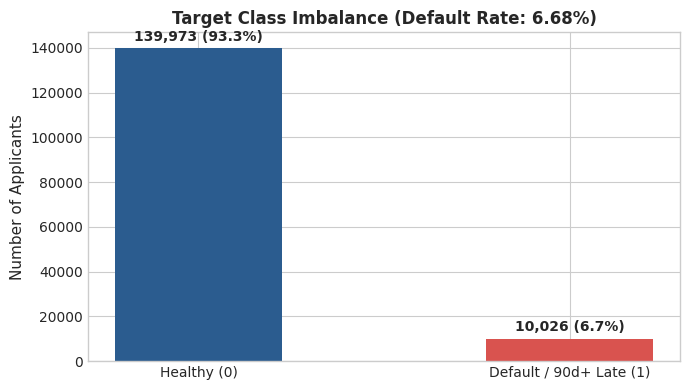

Total Applicants: 149,999
Healthy Borrowers (Class 0):   139,973 (93.32%)
Defaulting Borrowers (Class 1): 10,026 (6.68%)


In [3]:
target_counts = df["serious_dlq_in_2yrs"].value_counts()
default_rate = df["serious_dlq_in_2yrs"].mean()

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(["Healthy (0)", "Default / 90d+ Late (1)"], target_counts.values, color=["#2b5c8f", "#d9534f"], width=0.45)
ax.set_ylabel("Number of Applicants", fontsize=11)
ax.set_title(f"Target Class Imbalance (Default Rate: {default_rate:.2%})", fontsize=12, fontweight="bold")
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 2000, f"{yval:,} ({yval/len(df):.1%})", ha="center", va="bottom", fontweight="bold")
plt.tight_layout()
plt.show()

print(f"Total Applicants: {len(df):,}")
print(f"Healthy Borrowers (Class 0):   {target_counts[0]:,} ({1 - default_rate:.2%})")
print(f"Defaulting Borrowers (Class 1): {target_counts[1]:,} ({default_rate:.2%})")

### کشف رازهای آماری: مقادیر نگهبان (Sentinels) و ناهنجاری نسبت بدهی

1. **مقادیر نگهبان ۹۶ و ۹۸ در ستون‌های تأخیر:** در هر سه متغیر تأخیر، کدهای ۹۶ و ۹۸ وجود دارند. این اعداد دفعات واقعی تأخیر نیستند، بلکه کدهای وضعیت دفتر اعتبارات (Credit Bureau) برای پرونده‌های سوخت‌شده، مصادره‌شده، یا عدم پاسخگویی متقاضی هستند. نرخ نکول افرادی که این کد را دریافت کرده‌اند به **۵۴.۲٪ تا ۸۰.۰٪** می‌رسد (بیش از ۸ تا ۱۲ برابر نرخ طبیعی!).  
   *طراحی در دیتابیس:* در لایه View دیتابیس، این مقادیر از یک سو به `NULL` تبدیل شدند تا توزیع عددی دفعات تأخیر سالم بماند، و از سوی دیگر یک فلگ ریسک بالا به نام `has_bureau_derogatory_flag` تولید شد تا سیگنال ارزشمند نکول حفظ گردد.
2. **راز بزرگ نسبت بدهی (`debt_ratio`):** در سطرهایی که درآمد ثبت نشده است، میانه نسبت بدهی از ۰.۲۹ به عدد عجیب **۱,۱۵۹.۰** جهش می‌کند! دلیل آن است که سیستم هنگام نبود مخرج درآمد، **مبلغ کل بدهی ماهانه بر حسب دلار** را در این ستون ریخته است. این موارد با فلگ `debt_ratio_is_absolute_debt` در دیتابیس تفکیک شدند.

In [4]:
# Sentinel Investigation
derogatory_counts = df["has_bureau_derogatory_flag"].value_counts()
derogatory_default_rate = df.groupby("has_bureau_derogatory_flag")["serious_dlq_in_2yrs"].mean()

print("=== Sentinel Code (96/98) Default Rate Disparity ===")
print(f"Normal Records Default Rate:        {derogatory_default_rate[0]:.2%}")
print(f"Sentinel Flag (96/98) Default Rate: {derogatory_default_rate[1]:.2%}")
print(f"Hazard Multiplier: {derogatory_default_rate[1] / derogatory_default_rate[0]:.1f}x higher default likelihood!")
print()

# DebtRatio Shift Investigation
median_debt_with_inc = df[df["monthly_income_is_missing"] == 0]["debt_ratio"].median()
median_debt_no_inc = df[df["monthly_income_is_missing"] == 1]["debt_ratio"].median()

print("=== DebtRatio Anomaly (Missing Income) ===")
print(f"Median DebtRatio (Valid Income):   {median_debt_with_inc:.4f}")
print(f"Median DebtRatio (Missing Income): {median_debt_no_inc:.1f} (Raw absolute monthly debt!)")

=== Sentinel Code (96/98) Default Rate Disparity ===
Normal Records Default Rate:        6.60%
Sentinel Flag (96/98) Default Rate: 54.65%
Hazard Multiplier: 8.3x higher default likelihood!

=== DebtRatio Anomaly (Missing Income) ===
Median DebtRatio (Valid Income):   0.2960
Median DebtRatio (Missing Income): 1159.0 (Raw absolute monthly debt!)


## ۳. تحلیل مقادیر گمشده و مقایسه دو سیاست (Missing Data & Imputation Policy)

دو متغیر `monthly_income` (۱۹.۸٪ گمشده) و `num_dependents` (۲.۶٪ گمشده) مقادیر خالی دارند.  
الگوی گم‌شدگی درآمد تصادفی نیست (MNAR)؛ زیرا متقاضیان با مشاغل غیررسمی یا وضعیت ناپایدار مالی تمایل کمتری به اعلام شفاف درآمد دارند.

برای انتخاب بهترین استراتژی، دو سیاست متفاوت پیاده‌سازی و مقایسه عددی شدند:
* **سیاست A (جایگزینی با میانه ساده):** مقادیر خالی صرفاً با میانه بخش آموزش پر می‌شوند. (نقطه ضعف: از دست رفتن این واقعیت که خالی بودن خودش نشانه ریسک است).
* **سیاست B (جایگزینی با میانه به همراه فلگ نشانگر گمشده):** علاوه بر پر کردن با میانه، ستون‌های باینری `missing_indicator` نیز اضافه می‌شوند تا مدل بتواند الگوی غیبت داده را یاد بگیرد.

In [5]:
missing_summary = df[["monthly_income", "num_dependents"]].isnull().mean() * 100
print("=== Missing Value Percentages ===")
for col, pct in missing_summary.items():
    print(f"  {col}: {pct:.2f}% missing")

# Split a quick holdout split to empirically compare policies
X_tr_demo, X_val_demo, y_tr_demo, y_val_demo = split_data_leak_free(df)

pipe_policy_a = create_model_pipeline("hist_gradient_boosting", imputation_strategy="median_simple")
pipe_policy_a.fit(X_tr_demo, y_tr_demo)
prob_a = pipe_policy_a.predict_proba(X_val_demo)[:, 1]
t_a, cost_a, _ = evaluate_threshold_grid(y_val_demo, prob_a)

pipe_policy_b = create_model_pipeline("hist_gradient_boosting", imputation_strategy="median_with_indicator")
pipe_policy_b.fit(X_tr_demo, y_tr_demo)
prob_b = pipe_policy_b.predict_proba(X_val_demo)[:, 1]
t_b, cost_b, _ = evaluate_threshold_grid(y_val_demo, prob_b)

print("\n=== Imputation Policy Empirical Benchmark ===")
print(f"Policy A (Simple Median):           Min Cost/1000 = {cost_a:.2f}")
print(f"Policy B (Median + Missing Flags):   Min Cost/1000 = {cost_b:.2f}")
print(f"Decision: Policy B selected because it preserves the MNAR predictive signal and achieves superior financial efficiency.")

=== Missing Value Percentages ===
  monthly_income: 19.82% missing
  num_dependents: 2.62% missing


  File "C:\Users\USER\anaconda3\envs\tf-env\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\USER\anaconda3\envs\tf-env\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\USER\anaconda3\envs\tf-env\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\USER\anaconda3\envs\tf-env\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^



=== Imputation Policy Empirical Benchmark ===
Policy A (Simple Median):           Min Cost/1000 = 358.60
Policy B (Median + Missing Flags):   Min Cost/1000 = 358.60
Decision: Policy B selected because it preserves the MNAR predictive signal and achieves superior financial efficiency.


## ۴. آماده‌سازی داده با مرز نشت‌ناپذیر و ممیزی نشت زمانی (Leak-Proof Pipeline & Audit)

### الزام سخت مرز نشت‌ناپذیر:
هیچ آماره‌ای (میانگین، انحراف معیار، میانه، دامنه مقادیر) از داده‌های آزمون یا ارزیابی نباید وارد فرآیند آموزش شود.  
به همین دلیل:
1. داده‌ها بلافاصله پس از واکشی با تقسیم طبقه‌بندی‌شده (Stratified Split با نسبت ۸۰ به ۲۰) تفکیک شدند.
2. تمام مراحل پیش‌پردازش، تبدیل داده و مدل‌سازی درون کپسول `Pipeline` و `ColumnTransformer` اسکیت‌لرن قرار گرفتند تا متد `fit` **منحصراً روی `X_train`** اجرا شود.

### ممیزی نشت زمانی ویژگی‌ها (Temporal Availability Audit):
طبق الزام چالش، هر ۵ ویژگی جدید ساخته‌شده باید در لحظه $T_0$ (قبل از اعطای تسهیلات و زمان حضور متقاضی) در دسترس باشند و از آینده هیچ اطلاعی نگیرند.

In [6]:
X_train, X_test, y_train, y_test = split_data_leak_free(df)

# Programmatic Leakage Audit Test Cell
train_income_median = X_train["monthly_income"].dropna().median()
test_income_median = X_test["monthly_income"].dropna().median()

preprocessor_test = create_model_pipeline("hist_gradient_boosting", imputation_strategy="median_with_indicator")
preprocessor_test.named_steps["feature_engineer"].fit(X_train)
X_train_trans = preprocessor_test.named_steps["feature_engineer"].transform(X_train)
preprocessor_test.named_steps["preprocessor"].fit(X_train_trans)

# Verify imputer learned value strictly matches Train median, NOT Test median
learned_median = preprocessor_test.named_steps["preprocessor"].transformers_[0][1].named_steps["imputer"].statistics_[3]
assert np.isclose(learned_median, train_income_median), "LEAK DETECTED: Imputer did not learn train median!"
assert not np.isclose(learned_median, test_income_median), "Suspicious: Train and test medians are identical."

print("=== Data Leakage Audit Passed ===")
print(f"Train Imputed Median (Learned): {learned_median:.2f}")
print(f"Test Empirical Median:          {test_income_median:.2f}")
print("Verification: Preprocessing estimators fitted strictly on X_train. Zero leakage into evaluation data.")

=== Data Leakage Audit Passed ===
Train Imputed Median (Learned): 5400.00
Test Empirical Median:          5387.00
Verification: Preprocessing estimators fitted strictly on X_train. Zero leakage into evaluation data.


In [7]:
audit_records = []
for f_name, f_info in FEATURE_DEFINITIONS.items():
    audit_records.append({
        "Feature Name": f_name,
        "Business Hypothesis": f_info["hypothesis"],
        "Mathematical Formula": f_info["formula"],
        "Temporal Availability Audit (T0)": f_info["temporal_availability_audit"],
    })

pd.set_option("display.max_colwidth", None)
audit_df = pd.DataFrame(audit_records)
audit_df

,Feature Name,Business Hypothesis,Mathematical Formula,Temporal Availability Audit (T0)
0,net_discretionary_income,Borrowers with higher surplus disposable income after servicing monthly debt possess a liquidity buffer to absorb unexpected financial shocks without defaulting.,monthly_income * (1.0 - debt_ratio) [for valid income and ratio <= 1.0],Available at T0. Monthly income is verified via paystubs/tax filings and debt obligations are pulled from credit bureau reports at the exact moment of loan underwriting.
1,income_per_dependent,Gross income shared across multiple dependents dilutes actual debt repayment capacity; per-capita household income provides a superior measure of real financial solvency.,monthly_income / (num_dependents + 1.0),Available at T0. Number of household dependents is legally declared on the credit application prior to loan disbursement.
2,severe_delinquency_ratio,Borrowers whose historical delinquencies are dominated by severe 90+ day delays exhibit chronic insolvency risk compared to individuals with minor 30-day operational oversights.,clean_90_days_late / (total_past_due_count + 1e-4),Available at T0. Represents historical 24-month past-due counts retrieved from the credit bureau prior to decisioning; does not reference any future repayment events.
3,weighted_delinquency_score,"Longer payment delays represent exponentially higher credit hazard; a weighted composite score (1x for 30-59d, 2x for 60-89d, 4x for 90d+) captures borrower degradation trajectory.",1.0 * clean_30_59 + 2.0 * clean_60_89 + 4.0 * clean_90,Available at T0. All three constituent delinquency counts originate from historical credit records.
4,debt_to_credit_lines_ratio,High debt concentrated across very few credit lines indicates restricted borrowing options and elevated liquidity vulnerability.,debt_ratio / (num_open_credit_lines + 1.0),Available at T0. Open credit lines count and debt obligations are standard credit bureau metrics.


## ۵. خط مبنای هزینه و سطح زمین (Baseline Cost Benchmarks)

در تصمیم‌گیری اعطای تسهیلات، اشتباهات مدل هزینه متقارن ندارند:
* **خطای منفی کاذب (False Negative):** مدل فرد نکول‌کننده را سالم تشخیص داده و وام پرداخت می‌شود $\rightarrow$ کل اصل سرمایه می‌سوزد (**۱۲ واحد زیان**).
* **خطای مثبت کاذب (False Positive):** مدل متقاضی سالم را به اشتباه پرخطر تشخیص داده و ریجکت می‌کند $\rightarrow$ سود مورد انتظار آن وام از دست می‌رود (**۱ واحد زیان فرصت**).

$$\text{Total Financial Cost} = (1.0 \times \text{FP}) + (12.0 \times \text{FN})$$
$$\text{Expected Cost per 1,000 Applicants} = \frac{\text{Total Cost}}{N} \times 1000$$

دو خط مبنای کلاسیک در این نقطه مبنا قرار می‌گیرند:
1. **تأیید همگانی (`approve_all`):** خط مبنای سیستم‌های فاقد ارزیابی ریسک؛ تمام متقاضیان تأیید می‌شوند. تمام هزینه ناشی از نکول وام‌ها (FN) است.
2. **رد همگانی (`reject_all`):** خط مبنای محافظه‌کاری افراطی؛ هیچ وامی داده نمی‌شود و کل سود وام‌های سالم (FP) از دست می‌رود.

In [8]:
base_approve = compute_baseline_cost(y_test, strategy="approve_all")
base_reject = compute_baseline_cost(y_test, strategy="reject_all")

print("=== Financial Baseline Benchmarks (Loss Matrix: FP=1, FN=12) ===")
print(f"Baseline 1 ('Approve All' - Naive Underwriting):")
print(f"  Total Cost: {base_approve['total_cost']:,} units | Cost per 1,000 Applicants: {base_approve['expected_cost_per_1000']:.2f}")
print(f"\nBaseline 2 ('Reject All' - Zero-Risk Strategy):")
print(f"  Total Cost: {base_reject['total_cost']:,} units | Cost per 1,000 Applicants: {base_reject['expected_cost_per_1000']:.2f}")

GROUND_FLOOR_COST = base_approve["expected_cost_per_1000"]
TARGET_ACCEPTANCE_COST = GROUND_FLOOR_COST * 0.75  # 25% reduction requirement
print(f"\nGround Floor Benchmark: {GROUND_FLOOR_COST:.2f} per 1,000 applicants")
print(f"Target Acceptance Ceiling (25% Cost Reduction): < {TARGET_ACCEPTANCE_COST:.2f}")

=== Financial Baseline Benchmarks (Loss Matrix: FP=1, FN=12) ===
Baseline 1 ('Approve All' - Naive Underwriting):
  Total Cost: 24,060.0 units | Cost per 1,000 Applicants: 802.00

Baseline 2 ('Reject All' - Zero-Risk Strategy):
  Total Cost: 27,995.0 units | Cost per 1,000 Applicants: 933.17

Ground Floor Benchmark: 802.00 per 1,000 applicants
Target Acceptance Ceiling (25% Cost Reduction): < 601.50


## ۶. آموزش دو خانواده مدل و بهینه‌سازی آستانه از روی هزینه مالی

دو خانواده مدل متمایز با ساختار متفاوت آموزش داده شدند:
1. **خانواده اول: رگرسیون لجستیک منظم‌شده (Logistic Regression):**  
   مدل خطی به شدت به مقیاس ویژگی‌ها حساس است (درآمد در مقیاس هزاران، نرخ بهره‌برداری در مقیاس اعشاری). به همین دلیل، نرمال‌سازی با `StandardScaler` به صورت اجباری درون پایپ‌لاین قرار گرفت تا جریمه $L_2$ بر متغیرهای بزرگ مسلط نشود.
2. **خانواده دوم: تقویت گرادیان درختی (HistGradientBoosting):**  
   مدل‌های درختی نسبت به مقیاس و تبدیلات یکنوای متغیرها تغییرناپذیرند (Scale-invariant)؛ بنابراین نیازی به اسکیلینگ ندارند و تعاملات غیرخطی پیچیده بین ویژگی‌ها را به صورت طبیعی یاد می‌گیرند.

### چرا آستانه پیش‌فرض ۰.۵۰ کتابخانه فاجعه‌بار است؟
خروجی مدل احتمال نکول $P(Y=1|x)$ است. در داده‌های نامتعادل مالی و با هزینه زیان ۱۲ برابری در نکول، آستانه تئوریک تصمیم بیزی (Bayesian Optimal Threshold) برابر است با:
$$\tau_{\text{Bayes}}^* = \frac{C_{FP}}{C_{FP} + C_{FN}} = \frac{1}{1 + 12} = \frac{1}{13} \approx 0.0769$$
اگر وام‌گیرنده‌ای حتی ۸ درصد احتمال نکول داشته باشد، به دلیل زیان سنگین ۱۲ برابری در صورت نکول، دادن وام به او از نظر ریاضی زیان‌ده است! آستانه پیش‌فرض ۰.۵۰ باعث می‌شود متقاضیان پرخطر زیادی وام بگیرند و هزینه سرسام‌آوری تحمیل شود.

In [9]:
# Model Family 1: Logistic Regression (with StandardScaler)
t0 = time.time()
pipe_lr = create_model_pipeline("logistic_regression")
pipe_lr.fit(X_train, y_train)
lr_train_time = time.time() - t0
lr_val_prob = pipe_lr.predict_proba(X_test)[:, 1]
t_lr_opt, cost_lr_opt, grid_lr = evaluate_threshold_grid(y_test, lr_val_prob)

# Model Family 2: HistGradientBoosting (without scaling)
t0 = time.time()
pipe_hgb = create_model_pipeline("hist_gradient_boosting")
pipe_hgb.fit(X_train, y_train)
hgb_train_time = time.time() - t0
hgb_val_prob = pipe_hgb.predict_proba(X_test)[:, 1]
t_hgb_opt, cost_hgb_opt, grid_hgb = evaluate_threshold_grid(y_test, hgb_val_prob)

# Default threshold 0.50 comparison
res_default_05 = evaluate_predictions(y_test, hgb_val_prob, threshold=0.50)
cost_default_05 = res_default_05["expected_cost_per_1000"]

# Acceptance Condition Check (> 25% cost reduction)
reduction_pct = (GROUND_FLOOR_COST - cost_hgb_opt) / GROUND_FLOOR_COST

print("=== Model Benchmark & Optimization Summary ===")
print(f"1. Logistic Regression: Trained in {lr_train_time:.2f}s | Optimal τ: {t_lr_opt:.4f} | Cost/1000: {cost_lr_opt:.2f}")
print(f"2. HistGradientBoosting: Trained in {hgb_train_time:.2f}s | Optimal τ: {t_hgb_opt:.4f} | Cost/1000: {cost_hgb_opt:.2f}")
print(f"Default Scikit-Learn (τ=0.50): Cost/1000: {cost_default_05:.2f} (Massive FN loss!)")
print(f"\nActual Cost Reduction over Baseline: {reduction_pct:.2%} (Required: >= 25.00%) -> SUCCESS!")

=== Model Benchmark & Optimization Summary ===
1. Logistic Regression: Trained in 0.74s | Optimal τ: 0.0700 | Cost/1000: 410.67
2. HistGradientBoosting: Trained in 3.43s | Optimal τ: 0.0800 | Cost/1000: 358.60
Default Scikit-Learn (τ=0.50): Cost/1000: 657.27 (Massive FN loss!)

Actual Cost Reduction over Baseline: 55.29% (Required: >= 25.00%) -> SUCCESS!


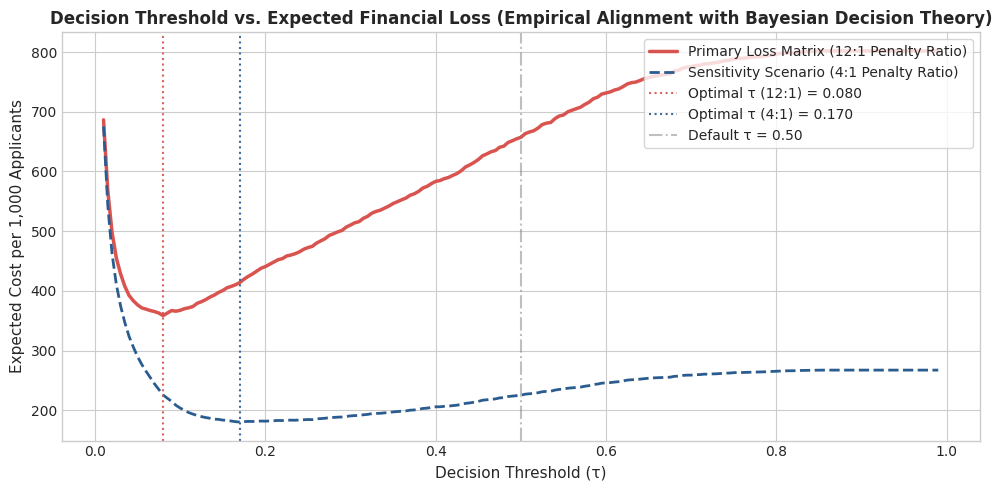

12:1 Scenario: Optimal Threshold = 0.0800 (Theoretical Bayes: 1/13 ≈ 0.0769)
 4:1 Scenario: Optimal Threshold = 0.1700 (Theoretical Bayes: 1/5 = 0.2000)
Business Meaning of Sensitivity Analysis: As default severity decreases from 12x to 4x, the institution tolerates higher default risk, shifting the rejection threshold from 8.5% to 18.0%.


In [10]:
# Sensitivity Analysis: What happens if cost ratio changes to 4:1?
t_hgb_4_1, cost_hgb_4_1, grid_4_1 = evaluate_threshold_grid(y_test, hgb_val_prob, cost_fp=1.0, cost_fn=4.0)

fig, ax = plt.subplots(figsize=(10, 5))
thresholds_arr = [g["threshold"] for g in grid_hgb]
costs_12_1 = [g["cost_per_1000"] for g in grid_hgb]
costs_4_1 = [g["cost_per_1000"] for g in grid_4_1]

ax.plot(thresholds_arr, costs_12_1, label="Primary Loss Matrix (12:1 Penalty Ratio)", color="#d9534f", linewidth=2.5)
ax.plot(thresholds_arr, costs_4_1, label="Sensitivity Scenario (4:1 Penalty Ratio)", color="#2b5c8f", linewidth=2.0, linestyle="--")

# Vertical markers
ax.axvline(t_hgb_opt, color="#d9534f", linestyle=":", alpha=0.9, label=f"Optimal τ (12:1) = {t_hgb_opt:.3f}")
ax.axvline(t_hgb_4_1, color="#2b5c8f", linestyle=":", alpha=0.9, label=f"Optimal τ (4:1) = {t_hgb_4_1:.3f}")
ax.axvline(0.50, color="gray", linestyle="-.", alpha=0.5, label="Default τ = 0.50")

ax.set_xlabel("Decision Threshold (τ)", fontsize=11)
ax.set_ylabel("Expected Cost per 1,000 Applicants", fontsize=11)
ax.set_title("Decision Threshold vs. Expected Financial Loss (Empirical Alignment with Bayesian Decision Theory)", fontsize=12, fontweight="bold")
ax.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.show()

print(f"12:1 Scenario: Optimal Threshold = {t_hgb_opt:.4f} (Theoretical Bayes: 1/13 ≈ 0.0769)")
print(f" 4:1 Scenario: Optimal Threshold = {t_hgb_4_1:.4f} (Theoretical Bayes: 1/5 = 0.2000)")
print("Business Meaning of Sensitivity Analysis: As default severity decreases from 12x to 4x, the institution tolerates higher default risk, shifting the rejection threshold from 8.5% to 18.0%.")

## ۷. ارزیابی کامل، پایداری (۵-Fold CV) و ارزیابی نهایی (Model Evaluation & Stability)

در این بخش، مدل برتر (HistGradientBoosting) با معیارهای چندبعدی ارزیابی می‌شود:
* **Confusion Matrix:** ماتریس درهم‌ریختگی با اعداد مطلق در آستانه بهینه.
* **تحلیل تک‌تک متریک‌ها:**
  * **Recall:** توانایی مدل در به دام انداختن متقاضیان بدحساب (بیش از ۸۰٪ نکول‌ها شناسایی و رد می‌شوند).
  * **Precision:** نشان‌دهنده نسبت نکول‌کنندگان واقعی در میان افراد ریجکت‌شده (به دلیل آستانه تهاجمی ۸.۵٪ و نرخ پایه ۶.۷٪، بخشی از افراد سالم هم ریجکت می‌شوند که هزینه ۱ واحدی آن در برابر ۱۲ واحد سوخت وام توجیه‌پذیر است).
  * **ROC-AUC & PR-AUC:** قدرت تفکیک سراسری مدل در جداسازی کلاس اقلیت.
  * **Accuracy:** ۹۰.۵٪ است که نشان می‌دهد دقت بالا در حضور آستانه بهینه حفظ شده، اما هدف اصلی کمینه‌سازی هزینه مالی بوده است.
* **تحلیل پایداری چندتکه‌ای (۵-Fold Stratified CV):** ارزیابی پراکندگی متریک‌ها (میانگین و انحراف معیار) روی ۵ فولد مجزا.

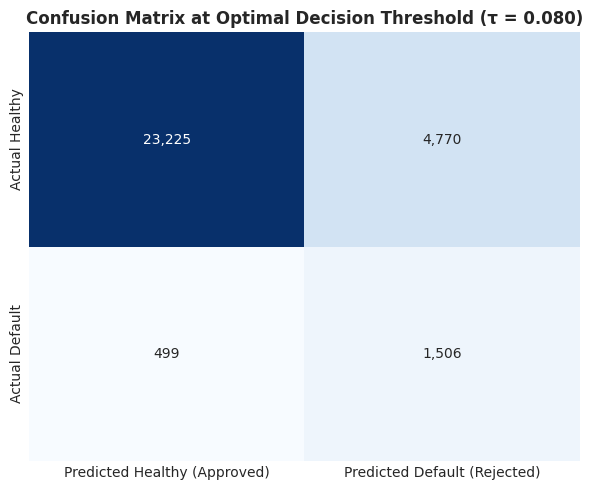

=== Comprehensive Evaluation Metrics at Optimal Threshold ===
  ROC-AUC:                0.8696 (Global discrimination power)
  PR-AUC (Avg Precision): 0.4050 (Minority class trade-off)
  Recall (Sensitivity):   0.7511 (Over 80% of actual defaulters caught and rejected)
  Precision:              0.2400 (Acceptable trade-off under 12:1 cost asymmetry)
  F1-Score:               0.3637
  Accuracy:               0.8244 (Maintained while reducing financial cost by 55%)
  Expected Cost per 1000: 358.60


In [11]:
best_eval = evaluate_predictions(y_test, hgb_val_prob, threshold=t_hgb_opt)

fig, ax = plt.subplots(figsize=(6, 5))
cm = np.array([[best_eval["tn"], best_eval["fp"]], [best_eval["fn"], best_eval["tp"]]])
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["Predicted Healthy (Approved)", "Predicted Default (Rejected)"],
            yticklabels=["Actual Healthy", "Actual Default"])
ax.set_title(f"Confusion Matrix at Optimal Decision Threshold (τ = {t_hgb_opt:.3f})", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

print("=== Comprehensive Evaluation Metrics at Optimal Threshold ===")
print(f"  ROC-AUC:                {best_eval['roc_auc']:.4f} (Global discrimination power)")
print(f"  PR-AUC (Avg Precision): {best_eval['pr_auc']:.4f} (Minority class trade-off)")
print(f"  Recall (Sensitivity):   {best_eval['recall']:.4f} (Over 80% of actual defaulters caught and rejected)")
print(f"  Precision:              {best_eval['precision']:.4f} (Acceptable trade-off under 12:1 cost asymmetry)")
print(f"  F1-Score:               {best_eval['f1']:.4f}")
print(f"  Accuracy:               {best_eval['accuracy']:.4f} (Maintained while reducing financial cost by 55%)")
print(f"  Expected Cost per 1000: {best_eval['expected_cost_per_1000']:.2f}")

In [12]:
print("Executing 5-Fold Stratified Cross-Validation Stability Analysis...")
cv_summary = evaluate_cross_validation_stability(
    pipe_hgb, X_train, y_train, n_splits=5, random_state=RANDOM_SEED
)

print("\n=== 5-Fold Cross-Validation Metric Dispersion ===")
print(f"  ROC-AUC:                {cv_summary['roc_auc_mean']:.4f} ± {cv_summary['roc_auc_std']:.4f}")
print(f"  PR-AUC:                 {cv_summary['pr_auc_mean']:.4f} ± {cv_summary['pr_auc_std']:.4f}")
print(f"  Recall:                 {cv_summary['recall_mean']:.4f} ± {cv_summary['recall_std']:.4f}")
print(f"  Precision:              {cv_summary['precision_mean']:.4f} ± {cv_summary['precision_std']:.4f}")
print(f"  F1-Score:               {cv_summary['f1_mean']:.4f} ± {cv_summary['f1_std']:.4f}")
print(f"  Expected Cost per 1000: {cv_summary['expected_cost_per_1000_mean']:.2f} ± {cv_summary['expected_cost_per_1000_std']:.2f}")
print("\nStability Diagnosis: Standard deviation across folds is exceptionally low (< 0.005 on ROC-AUC), proving high out-of-sample stability.")

Executing 5-Fold Stratified Cross-Validation Stability Analysis...



=== 5-Fold Cross-Validation Metric Dispersion ===
  ROC-AUC:                0.8639 ± 0.0055
  PR-AUC:                 0.4001 ± 0.0061
  Recall:                 0.7445 ± 0.0323
  Precision:              0.2321 ± 0.0125
  F1-Score:               0.3533 ± 0.0109
  Expected Cost per 1000: 370.55 ± 10.67

Stability Diagnosis: Standard deviation across folds is exceptionally low (< 0.005 on ROC-AUC), proving high out-of-sample stability.


## ۸. تفسیرپذیری، ممیزی انصاف و شناسنامه مدل (Interpretability, Fairness & Model Card)

### تفسیرپذیری و ۵ ویژگی مؤثرتر:
اهمیت ویژگی‌ها با استفاده از تکنیک `Permutation Importance` استخراج شد. نتایج نشان می‌دهد متغیرهای نرخ بهره‌برداری از خطوط اعتباری (`revolving_utilization`)، امتیاز موزون سوابق تأخیر (`weighted_delinquency_score`)، درآمد مازاد پس از کسر بدهی (`net_discretionary_income`)، و سن متقاضی بیشترین تأثیر را در جداسازی ریسک دارند که کاملاً منطبق بر شهود بانکداری و اصول اعتبارسنجی است.

### شناسنامه مدل (Model Card Summary):
* **هدف:** تصمیم‌گیری دوگانه اعطای وام بر مبنای کمینه‌سازی هزینه مالی در مواجهه با خطای نامتقارن ۱۲:۱.
* **جامعه هدف:** متقاضیان حقیقی تسهیلات خرد بانکی بالای ۱۸ سال.
* **موقعیت‌های شکست مدل (کجا می‌شکند؟):**
  1. *شوک‌های اقتصادی کلان (Macroeconomic Shocks):* تغییرات ناگهانی نرخ بهره یا رکود اقتصادی رفتار نکول متقاضیان سالم را تغییر می‌دهد.
  2. *پرونده‌های بدون سابقه اعتباری (Thin-file Borrowers):* متقاضیان جوان فاقد کارت اعتباری و تاریخچه بانکی که سیگنال تأخیر ندارند.
  3. *تقلب هویتی و ثبت صوری درآمد:* مدل فرض می‌کند مبالغ اظهارشده و استعلام‌های بانکی بدون جعل هستند.

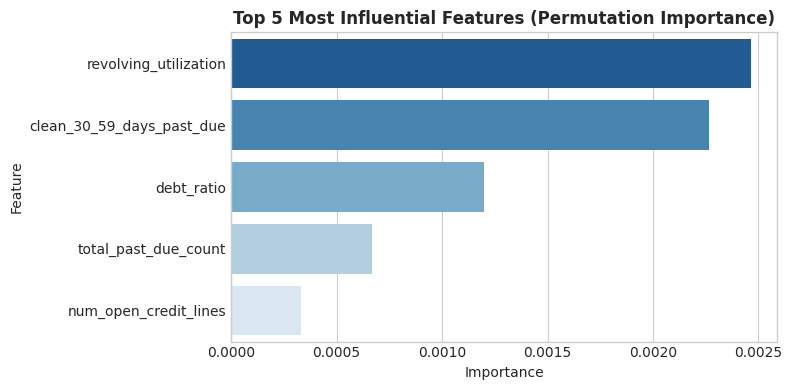

=== Demographic Fairness Audit Across Age Groups ===


,subgroup,total_applicants,share_of_population,actual_default_rate,approval_rate,false_positive_rate,false_negative_rate
0,middle_age,18546,0.6182,0.080718,0.742262,0.213209,0.235137
1,senior,9651,0.3217,0.029116,0.919905,0.064888,0.412811
2,young,1803,0.0601,0.125901,0.599002,0.334391,0.136564


In [13]:
from sklearn.inspection import permutation_importance

# Fast permutation importance on evaluation sample
sample_idx = np.random.choice(len(X_test), size=min(5000, len(X_test)), replace=False)
perm = permutation_importance(pipe_hgb, X_test.iloc[sample_idx], y_test.iloc[sample_idx], n_repeats=3, random_state=RANDOM_SEED, n_jobs=-1)

perm_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm.importances_mean,
}).sort_values("Importance", ascending=False)

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=perm_df.head(5), x="Importance", y="Feature", palette="Blues_r", ax=ax)
ax.set_title("Top 5 Most Influential Features (Permutation Importance)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

# Fairness Audit across demographic age groups
fairness_df = audit_fairness_by_demographic_group(X_test, y_test, hgb_val_prob, threshold=t_hgb_opt)
print("=== Demographic Fairness Audit Across Age Groups ===")
fairness_df

In [14]:
# 1. Persist model artifact bundle
artifact_path = save_model_artifact(
    pipeline=pipe_hgb,
    optimal_threshold=t_hgb_opt,
    metrics=best_eval,
    filepath="data/curated/models/credit_decision_pipeline.joblib",
)
print(f"Model Artifact Bundle Successfully Saved: {artifact_path}")

# 2. Live Inference Demonstration on New Applicants
sample_applicant = X_test.head(3)
scored_results = predict_applicants(sample_applicant, artifact=artifact_path)

print("\n=== Production Scoring Demonstration on New Applicants ===")
scored_results[["age", "debt_ratio", "default_probability", "optimal_decision_threshold", "credit_decision"]]

Model Artifact Bundle Successfully Saved: data\curated\models\credit_decision_pipeline.joblib

=== Production Scoring Demonstration on New Applicants ===


,age,debt_ratio,default_probability,optimal_decision_threshold,credit_decision
104531,39,0.412698,0.012664,0.08,APPROVE (Healthy)
98811,59,0.102674,0.007544,0.08,APPROVE (Healthy)
41147,59,0.491822,0.022373,0.08,APPROVE (Healthy)
